<a href="https://colab.research.google.com/github/AniShriyak/Bio-Inspired-Lab/blob/main/BIS_GreyWolf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 1 Best Fitness: 144.8905
Iteration: 2 Best Fitness: 144.8905
Iteration: 3 Best Fitness: 142.2503
Iteration: 4 Best Fitness: 142.2503
Iteration: 5 Best Fitness: 122.9486
Iteration: 6 Best Fitness: 122.9486
Iteration: 7 Best Fitness: 112.1541
Iteration: 8 Best Fitness: 112.1541
Iteration: 9 Best Fitness: 112.1541
Iteration: 10 Best Fitness: 112.1541
Iteration: 11 Best Fitness: 112.1541
Iteration: 12 Best Fitness: 102.4862
Iteration: 13 Best Fitness: 102.4862
Iteration: 14 Best Fitness: 102.4862
Iteration: 15 Best Fitness: 102.4862
Iteration: 16 Best Fitness: 102.4862
Iteration: 17 Best Fitness: 102.4862
Iteration: 18 Best Fitness: 102.4862
Iteration: 19 Best Fitness: 102.4322
Iteration: 20 Best Fitness: 102.4322
Iteration: 21 Best Fitness: 102.4322
Iteration: 22 Best Fitness: 102.4322
Iteration: 23 Best Fitness: 99.7683
Iteration: 24 Best Fitness: 99.7683
Iteration: 25 Best Fitness: 99.7683
Iteration: 26 Best Fitness: 95.785
Iteration: 27 Best Fitness: 94.251
Iteration: 28 Bes

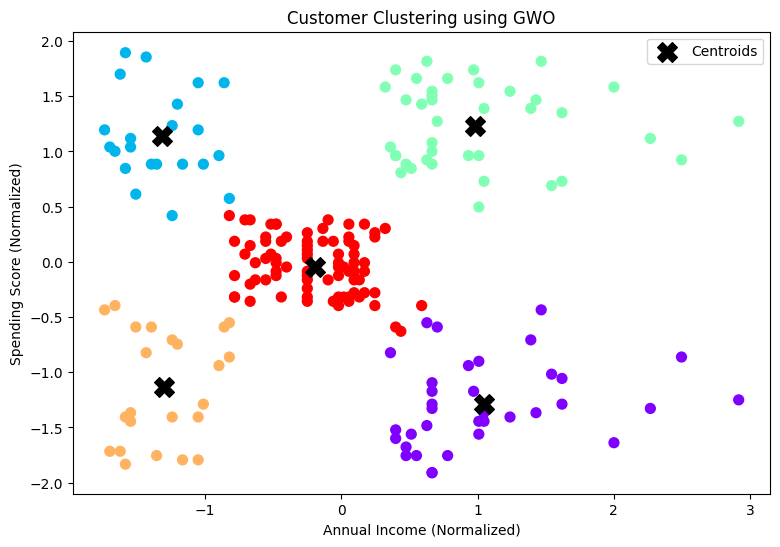

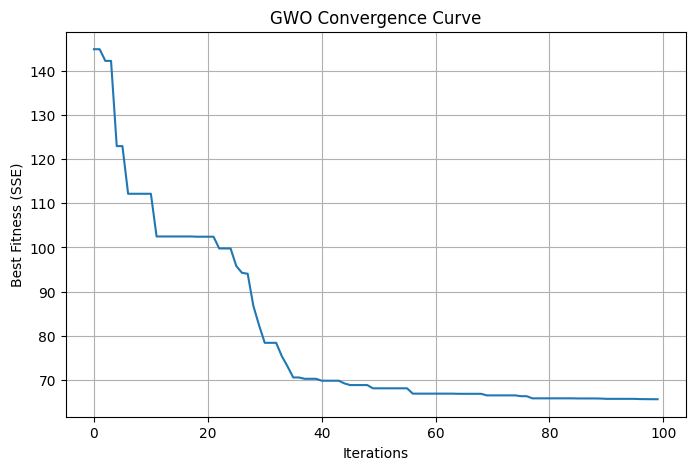

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


# ---------------------------------
# 1. LOAD DATASET
# ---------------------------------

df = pd.read_csv("/Mall_Customers.csv")

X = df[['Annual Income (k$)',
        'Spending Score (1-100)']].values

# Normalize data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Parameters
K = 5
N = 30
MAX_ITER = 100
DIM = K * 2

# Bounds of the dataset
lower = X.min(axis=0).min()
upper = X.max(axis=0).max()


# ---------------------------------
# 2. FITNESS FUNCTION
# ---------------------------------

def fitness(wolf):

    centroids = wolf.reshape(K, 2)

    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centroids,
        axis=2
    )

    min_distances = np.min(distances, axis=1)

    return np.sum(min_distances ** 2)


# ---------------------------------
# 3. INITIALIZE WOLVES
# ---------------------------------

wolves = np.random.uniform(
    lower, upper, (N, DIM)
)

alpha = np.zeros(DIM)
beta = np.zeros(DIM)
delta = np.zeros(DIM)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []


# ---------------------------------
# 4. GREY WOLF OPTIMIZATION
# ---------------------------------

for iteration in range(MAX_ITER):

    for i in range(N):

        score = fitness(wolves[i])

        if score < alpha_score:
            delta_score = beta_score
            delta = beta.copy()

            beta_score = alpha_score
            beta = alpha.copy()

            alpha_score = score
            alpha = wolves[i].copy()

        elif score < beta_score:
            delta_score = beta_score
            delta = beta.copy()

            beta_score = score
            beta = wolves[i].copy()

        elif score < delta_score:
            delta_score = score
            delta = wolves[i].copy()

    # Decrease a from 2 to 0
    a = 2 - 2 * iteration / MAX_ITER

    # Update positions of all wolves
    for i in range(N):

        for j in range(DIM):

            r1 = np.random.random()
            r2 = np.random.random()

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(C1 * alpha[j] - wolves[i][j])
            X1 = alpha[j] - A1 * D_alpha

            r1 = np.random.random()
            r2 = np.random.random()

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(C2 * beta[j] - wolves[i][j])
            X2 = beta[j] - A2 * D_beta

            r1 = np.random.random()
            r2 = np.random.random()

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(C3 * delta[j] - wolves[i][j])
            X3 = delta[j] - A3 * D_delta

            # Update wolf position
            wolves[i][j] = (X1 + X2 + X3) / 3

        # Keep positions within dataset bounds
        wolves[i] = np.clip(wolves[i], lower, upper)

    convergence.append(alpha_score)

    print("Iteration:", iteration + 1,
          "Best Fitness:", round(alpha_score, 4))


# ---------------------------------
# 5. GET OPTIMAL CLUSTER CENTROIDS
# ---------------------------------

best_centroids = alpha.reshape(K, 2)

# Assign each data point to nearest centroid
distances = np.linalg.norm(
    X[:, np.newaxis, :] - best_centroids,
    axis=2
)

labels = np.argmin(distances, axis=1)

# Convert centroids back to original scale
original_centroids = scaler.inverse_transform(
    best_centroids
)

print("\nOptimal Cluster Centroids:")
print(original_centroids)

print("\nCluster Distribution:")
print(pd.Series(labels).value_counts().sort_index())

print("\nSilhouette Score:",
      silhouette_score(X, labels))


# ---------------------------------
# 6. VISUALIZE CLUSTERS
# ---------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap='rainbow',
    s=50
)

plt.scatter(
    best_centroids[:, 0],
    best_centroids[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("Customer Clustering using GWO")
plt.xlabel("Annual Income (Normalized)")
plt.ylabel("Spending Score (Normalized)")
plt.legend()
plt.show()


# ---------------------------------
# 7. CONVERGENCE GRAPH
# ---------------------------------

plt.figure(figsize=(8, 5))

plt.plot(convergence)

plt.title("GWO Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness (SSE)")
plt.grid()

plt.show()
